In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math
import graphviz

In [2]:
def f(x):
    return (x**2+3.14)/x

def g(x):
    return x**2

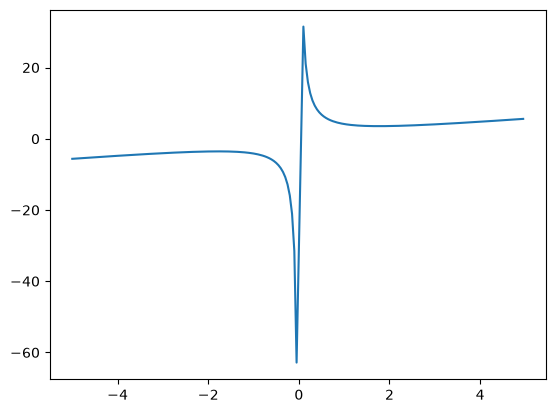

In [3]:
xs = np.arange(-5,5,.05)

bad_point = np.where((xs > -.05) & (xs < .05))
xs = np.delete(xs, bad_point)

ys = f(xs)
plt.plot(xs, ys)

-11.562512502498734


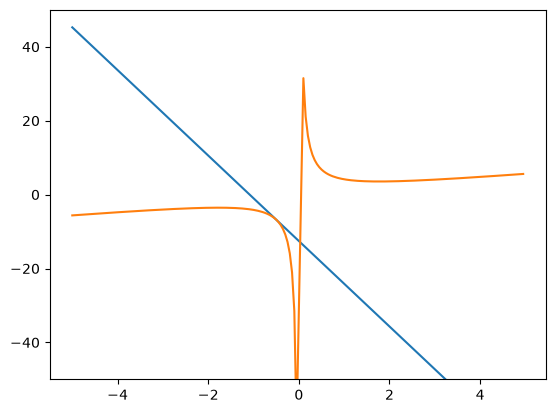

In [4]:
# find derivative line, and approximation
h = 0.0001
x = -0.5
f(x)
f(x+h)

# definition of slope at that point
slope = (f(x+h)-f(x))/h

# then we get b as a result by manipulating f(point) = point*slope + b
b = -(x * slope) + f(x)
def df_tan_line(xs, slope, b):
    return xs*slope + b

dys = df_tan_line(xs, slope, b)

# visual proof that this is the derivative
plt.plot(xs, dys)
plt.plot(xs, ys)
plt.ylim(-50, 50)
print(slope)


In [5]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        print_text = f"Value data=({self.data})"
        return print_text

    def __add__(self, b: Value):
        out = Value(self.data + b.data, (self, b), '+')
        return out

    def __mul__(self, b: Value):
        out = Value(self.data * b.data, (self, b), '*')
        return out

In [6]:
# recursively build out the graph to show all relations
def trace(root):
    nodes, edges = set(), set()
    # start at a node and build this tiny portion of the graph
    def build(node):
        # if the node isn't already in the graph, then add it, and then add its children
        if node not in nodes:    
            nodes.add(node)
            for child in node._prev:
                edges.add((child, node))
                # For each of its children repeat this process and they will 'go off on their own to build theirs'
                build(child)
    build(root)
    return nodes, edges



In [7]:
def make_computation_graph(loss_function_node):

    # Make the graph object
    dot = graphviz.Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    # Get all nodes and edges so we can prepare to actually make the graph viz
    nodes, edges = trace(loss_function_node)

    # Build all the nodes in space, and also build a special op node that already has an edge
    for node in nodes:
        uid = str(id(node))
        # build the node
        dot.node(name = uid, label = f'{{ {node.label} | {node.data:.4f} | grad {node.grad:.4f}}}', shape='record')
        if node._op:
            _op_name = uid + node._op
            # build the op node, and connect it to the parent immediately
            dot.node(name = _op_name, label=node._op)
            dot.edge(_op_name, uid)
    # for the rest of the edges, connect them to the floating nodes now
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot
    

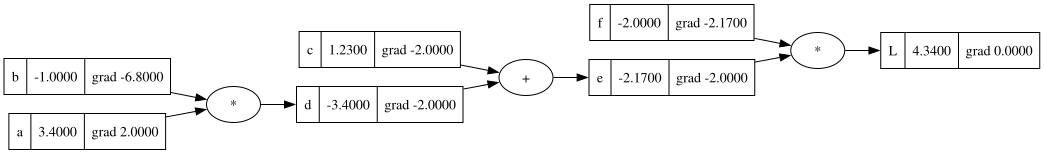

In [8]:
a = Value(3.4, label='a')
b = Value(-1.0, label='b')
c = Value(1.23, label='c') 
d = a*b; d.label='d'
e = d+c; e.label = 'e'
f = Value(-2.0, label='f')
L = e*f; L.label = 'L'

# We show how we got these down below
f.grad = -2.17# dL/df
e.grad = -2.0
d.grad = -2.0
c.grad = -2.0
a.grad = 2.0
b.grad = -6.8

make_computation_graph(L)

# By Hand
First we'll do the gradients by hand, complete them, and then verify the output using the approximate verification below

$$\frac{\partial L}{\partial L} = 1$$

$$\frac{\partial L}{\partial e} = \frac{\partial (e \cdot f)}{\partial e} = f = -2.0$$

$$\frac{\partial L}{\partial f} = \frac{\partial (e \cdot f)}{\partial f} = e = -2.17$$

## Chain Rule
Now we start getting into chain rule since we need to extend our rate of change beyond just the local derivative w.r.t $L$. Instead, we need to go further down into $d$ and $c$. We can think of this as gear ratios. If we move the $d$ gear by $h$ rotations, then $e$ will rotate accordingly, which then rotates $L$. The grad tells us by how much this rotation matters as it propagates to $L$.

$$\frac{\partial L}{\partial d} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial d} = -2.0 \cdot 1 = -2.0$$

$$\frac{\partial L}{\partial c} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial c} = -2.0 \cdot 1 = -2.0$$

$$\frac{\partial L}{\partial a} = \frac{\partial L}{\partial d} \cdot \frac{\partial d}{\partial a} = -2.0 \cdot -1.0 = 2.0$$

$$\frac{\partial L}{\partial b} = \frac{\partial L}{\partial d} \cdot \frac{\partial d}{\partial b} = -2.0 \cdot 3.4 = -6.8$$


In [13]:
f.grad = -2.17# dL/df
e.grad = -2.0
d.grad = -2.0
c.grad = -2.0
a.grad = 2.0
b.grad = -6.8


In [10]:
def verify_gradient():

    h = 0.0001

    a = 3.4
    b = -1.0
    c = 1.23
    d = a*b
    e = d+c
    f = -2.0
    L1 = e*f
    print(L1)

    a = 3.4
    a += h
    
    b = -1.0
    # b += h
    
    c = 1.23
    # c += h

    d = a*b
    # d += h

    e = d+c
    # e += h

    f = -2.0
    # f += h

    L2 = e*f
    print(L2, L1, (L2 - L1), round((L2-L1)/h, 11))

verify_gradient()

4.34
4.3402 4.34 0.00020000000000042206 2.0


# Optimization

Now we know how to influence the final outcome, which means we can adjust the final outcome by some meaningful amount to drive it up or down simply by modifying the constituent values that create it. For example, lets look at $L=x^2$ when $x=-1$

Then $\frac{\partial L}{\partial x} = 2x = -2$

Here we have a negative gradient so, ``x.grad`` would be -2. If we want to increase $L$, how do we do it? We can use the gradient to tell us exactly how. If take a tiny step forward through $x$, then $L$ will decrease with an instantaneous rate of -2, so we need to take a step to the left. How can we do this without checking? Well, the gradient tells us this right now! If we take a step by ``x.grad``, we will go in a _negative_ direction which will _increase_ $L$. Then, we can simply do ``x += 0.01 * x.grad``. In this case, we will be at -1, and we will add on 

$$0.01(-2) = -0.02 \implies -1 + -0.02 = -1.02$$

which takes in a step to the left, which increases $L$!

If instead we had a positive gradient, then we want to take a step to the right - in the positive direction - which is still encapsulated by 

$$x \gets x+0.01 \cdot \frac{\partial L}{\partial x}$$

Simply speaking, the gradient automatically tells you which direction to move the variable so that the final output is increased everytime. Doing this for every variable in your computation grad can tell you how to update every single variable (soon to be weights) to increase or decrease the loss.

In [19]:
# Previous work copied here so we can see this in isolation.

a = Value(3.4, label='a')
b = Value(-1.0, label='b')
c = Value(1.23, label='c') 
d = a*b; d.label='d'
e = d+c; e.label = 'e'
f = Value(-2.0, label='f')
L = e*f; L.label = 'L'

# We show how we got these down below
f.grad = -2.17# dL/df
e.grad = -2.0
d.grad = -2.0
c.grad = -2.0
a.grad = 2.0
b.grad = -6.8

print(L)

f.data += 0.01*f.grad
e.data += 0.01*e.grad 
d.data += 0.01*d.grad 
c.data += 0.01*c.grad 
a.data += 0.01*a.grad
b.data += 0.01*b.grad 

d = a*b
e = d+c
L_new = e*f

print(L_new)


Value data=(4.34)
Value data=(4.938123552)


[]

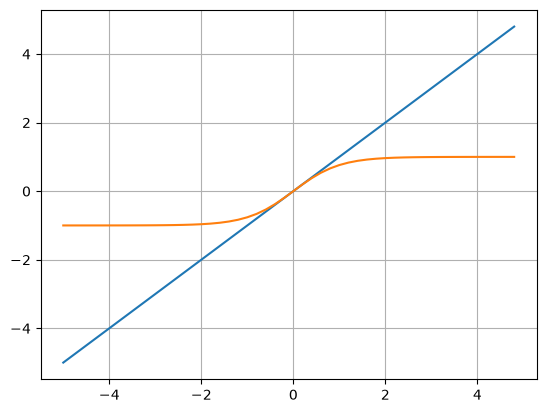

In [21]:
# Now we go over some activation functions like tanh to better understand basic neurons

# Standard linear function
plt.plot(np.arange(-5,5,0.2), np.arange(-5,5,0.2))
plt.grid(True)
plt.plot()

# Linear function activated, with squishes
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)))
plt.grid(True)
plt.plot()